In [1]:
import pandas as pd

train = pd.read_csv("../data/raw/financial_train.csv")
validation = pd.read_csv("../data/raw/financial_validation.csv")

y_train = (train["status_label"] == "failed").astype(int)
y_val = (validation["status_label"] == "failed").astype(int)

def new_ratios(data):
    ratios = pd.DataFrame()
    ratios["Liquidity"] = (data["3_current_assets"] - data["3_total_current_liabilities"]) / data["3_total_assets"]
    ratios["Retained_Earnings"] = data["3_retained_earnings"] / data["3_total_assets"]
    ratios["Operating_Profitability"] = data["3_ebit"] / data["3_total_assets"]
    ratios["Solvency"] = data["3_market_value"] / data["3_total_liabilities"]
    ratios["Asset_Turnover"] = data["3_net_sales"] / data["3_total_assets"]
    return ratios

X_train = new_ratios(train)
X_val = new_ratios(validation)

lower = X_train.quantile(0.01)
upper = X_train.quantile(0.99)
X_train = X_train.clip(lower, upper, axis=1)
X_val = X_val.clip(lower, upper, axis=1)

print(X_train.shape, X_val.shape)

(3142, 5) (233, 5)


In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

logregression = Pipeline([
    ("scale", StandardScaler()),
    ("logreg", LogisticRegression(class_weight="balanced", max_iter=1000))
])
logregression.fit(X_train, y_train);

## Random Forest

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

for leaf in [1, 5, 20, 50]:
    forest = RandomForestClassifier(
        n_estimators=500,
        max_features="sqrt",
        min_samples_leaf=leaf,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    )
    forest.fit(X_train, y_train)
    forest_prob = forest.predict_proba(X_val)[:, 1]
    print("min_samples_leaf:", leaf, "| PR-AUC:", round(average_precision_score(y_val, forest_prob), 3))

min_samples_leaf: 1 | PR-AUC: 0.363
min_samples_leaf: 5 | PR-AUC: 0.391
min_samples_leaf: 20 | PR-AUC: 0.44
min_samples_leaf: 50 | PR-AUC: 0.443


In [4]:
forest = RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    min_samples_leaf=50,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)
forest.fit(X_train, y_train);

**Tuning:** I used 500 trees with max_features="sqrt", and added class_weight="balanced" because bankruptcies are rare. I tried min_samples_leaf of 1, 5, 20 and 50 on the validation set.
PR-AUC was 0.363, 0.391, 0.440 and 0.443, so I chose 50. Small leaves overfit, because the trees memorise individual companies.

## Gradient Boosting

In [5]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

weights = compute_sample_weight("balanced", y_train)

for rate in [0.01, 0.05, 0.1, 0.3]:
    gb = GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=rate,
        max_depth=2,
        subsample=0.8,
        random_state=42
    )
    gb.fit(X_train, y_train, sample_weight=weights)
    gb_prob = gb.predict_proba(X_val)[:, 1]
    print("learning_rate:", rate, "| PR-AUC:", round(average_precision_score(y_val, gb_prob), 3))

learning_rate: 0.01 | PR-AUC: 0.387
learning_rate: 0.05 | PR-AUC: 0.436
learning_rate: 0.1 | PR-AUC: 0.43
learning_rate: 0.3 | PR-AUC: 0.368


In [6]:
gb = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=2,
    subsample=0.8,
    random_state=42
)
gb.fit(X_train, y_train, sample_weight=weights);

**Tuning:** I used 200 trees with max_depth=2 and subsample=0.8, and weighted bankrupt companies more heavily because they are rare. I tried learning rates of 0.01, 0.05, 0.1 and 0.3 on the validation set. 
PR-AUC was 0.387, 0.436, 0.43 and 0.368, so I chose 0.05. A high learning rate led to overfitting, while a low one didn’t learn enough in 200 trees.

## Results

In [7]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

def get_score(model):
    prob = model.predict_proba(X_val)[:, 1]
    pred = model.predict(X_val)
    return [
        average_precision_score(y_val, prob),
        roc_auc_score(y_val, prob),
        precision_score(y_val, pred, zero_division=0),
        recall_score(y_val, pred),
        f1_score(y_val, pred),
    ]

results = pd.DataFrame({
    "Majority class": get_score(baseline),
    "Logistic regression": get_score(logregression),
    "Random forest": get_score(forest),
    "Gradient boosting": get_score(gb),
}, index=["PR-AUC", "ROC-AUC", "Precision", "Recall", "F1"])

results.round(3)

,Majority class,Logistic regression,Random forest,Gradient boosting
PR-AUC,0.116,0.259,0.443,0.436
ROC-AUC,0.500,0.788,0.873,0.855
Precision,0.000,0.194,0.300,0.299
Recall,0.000,0.963,0.889,0.852
F1,0.000,0.323,0.449,0.442


**Results:** The random forest performed best, with a PR-AUC of 0.443, compared with 0.259 for logistic regression and 0.116 for a model with no skill. It caught 24 of the 27 bankruptcies, and 30% of the companies it flagged actually went bankrupt, up from 19% with logistic regression. Gradient boosting was a close second (PR-AUC 0.436). The validation set has only 27 bankruptcies, so the gap between the two tree models is too small to say one is truly better.

## Precision–recall curves

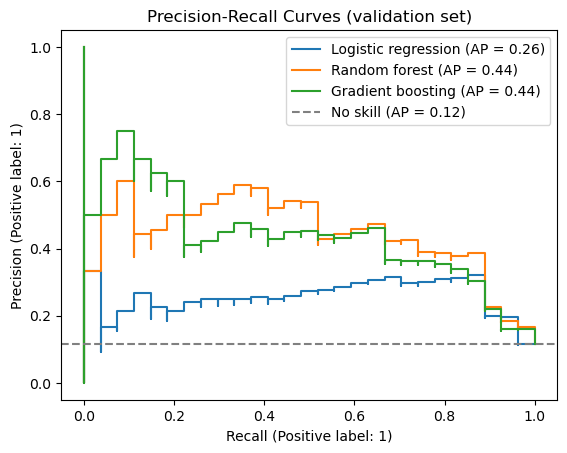

In [8]:
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt

ax = plt.gca()
PrecisionRecallDisplay.from_estimator(logregression, X_val, y_val, name="Logistic regression", ax=ax)
PrecisionRecallDisplay.from_estimator(forest, X_val, y_val, name="Random forest", ax=ax)
PrecisionRecallDisplay.from_estimator(gb, X_val, y_val, name="Gradient boosting", ax=ax)
plt.axhline(y_val.mean(), linestyle="--", color="grey", label="No skill (AP = 0.12)")
plt.legend()
plt.title("Precision-Recall Curves (validation set)")
plt.show()

Both tree models' curves sit above logistic regression's across most recall levels, so they raise fewer false alarms for the same number of bankruptcies caught. All three are well above the no-skill line (0.116).

## Error Analysis

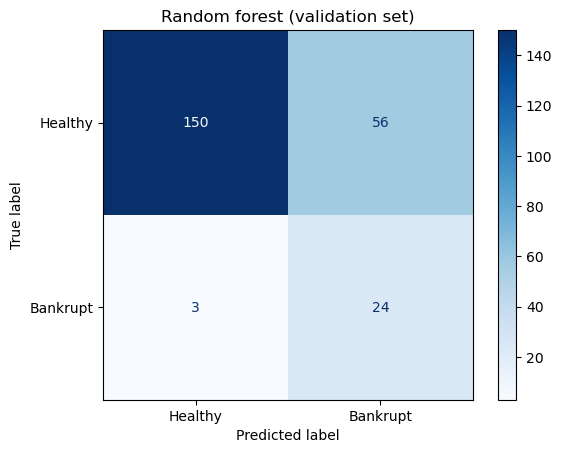

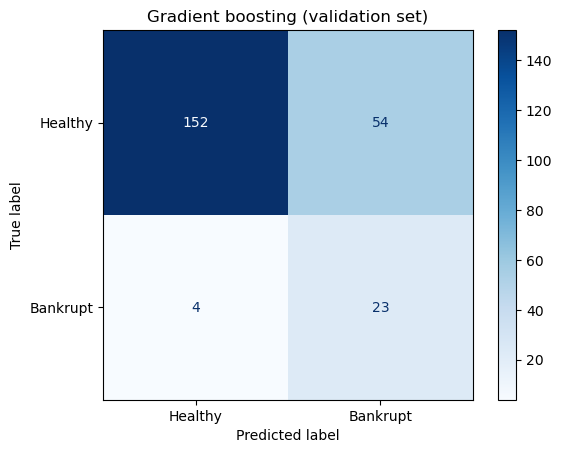

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(forest, X_val, y_val, display_labels=["Healthy", "Bankrupt"], cmap="Blues")
plt.title("Random forest (validation set)")
plt.show()

ConfusionMatrixDisplay.from_estimator(gb, X_val, y_val, display_labels=["Healthy", "Bankrupt"], cmap="Blues")
plt.title("Gradient boosting (validation set)")
plt.show()

The random forest catches 24 of the 27 bankruptcies and misses 3, but raises 56 false alarms. Gradient boosting catches 23 and raises 54 false alarms. Logistic regression raised 108 false alarms, so both tree models roughly halve them while missing only 2 or 3 more bankruptcies.

In [10]:
errors = X_val.copy()
errors["actual"] = y_val
errors["predicted"] = forest.predict(X_val)

table = errors.groupby(["actual", "predicted"]).median().round(2)
table.index = ["Correctly healthy", "False alarm", "Missed bankruptcy", "Caught bankruptcy"]
table["Companies"] = errors.groupby(["actual", "predicted"]).size().values
table

,Liquidity,Retained_Earnings,Operating_Profitability,Solvency,Asset_Turnover,Companies
Correctly healthy,0.23,-0.11,0.03,3.02,0.70,150
False alarm,-1.04,-8.74,-0.34,0.31,0.78,56
Missed bankruptcy,0.21,-0.51,0.03,1.77,1.40,3
Caught bankruptcy,-0.22,-0.82,-0.15,0.05,0.52,24


**Random Forest Error Analysis:**

- **False alarms (56):** These companies look even weaker than the real bankruptcies, with bigger losses and negative liquidity, but they survived. Their market value was higher compared with their debts, so investors seemed to expect them to recover.
- **Missed bankruptcies (3):** These looked healthy, with positive liquidity, roughly breaking even, and a solvency ratio close to healthy firms'. Their failure wasn't visible in the previous year's accounts.

So the model's mistakes come from companies whose accounts don't match what happened next. Only 3 bankruptcies were missed, so that group is too small to draw proper conclusions from.

## Draft conclusion

**Best model:** The random forest performed best, with a PR-AUC of 0.443 on the validation set, compared with 0.259 for logistic regression and 0.116 for no skill. It caught 24 of the 27 bankruptcies and raised roughly half as many false alarms as logistic regression. Gradient boosting came a close second (0.436). The clear result is that both tree models outperform logistic regression on the same five ratios.

**Limitations:**
- With only 27 bankruptcies in the validation set, the results are uncertain, and the two tree models can't be reliably separated.
- The settings were chosen using the validation set, so these scores are probably a little optimistic.
- The models use only five ratios from one year of accounts, which can't show every warning sign; the 3 missed bankruptcies looked healthy on paper.
- Bankruptcies are much rarer in the test years (2.6%), so test scores are likely to be lower.

**Next steps:**
- Add features showing how each ratio changed over the three years, since a worsening trend may give an earlier warning.
- Pick a cut-off other than 0.5, depending on whether missing a bankruptcy or raising a false alarm is more costly.
- Run the final model once on the test set.